# 16 · Prices from the swaps (work package 8)

**Work package 8** of the [implementation plan](../../research/implementation_plan.md), section 12.2. Every swap
against a base currency (WETH, USDC or USDT) gives a price: base amount per unit of the other token, from the two
amounts of the swap and the tokens' decimals (`src/scripts/prices.py`). The strategy's entries, exits and costs
rest on these prices, so this notebook checks them before anything else uses them.

Checks:

1. **Coverage:** how many swaps and tokens get a price, and why the others do not.
2. **Consistency across bases:** a token priced through WETH, USDC and USDT pools should get the same ETH price.
   This checks the decimals, the direction of each swap and the ETH price together.
3. **The ETH price** over the twelve weeks.
4. **The price-impact estimate** of `backtest.impact_estimate`: is it stable from one week to the next, and how
   often does it hit its 50% cap?

In [1]:
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import backtest as bt
import plots
import prices as px
import token_data as td

plots.style()
pd.set_option("display.float_format", "{:,.4f}".format)
OUT = td.PROJECT_DIR.parent.parent / "results" / "wp8"
OUT.mkdir(parents=True, exist_ok=True)

COLUMNS = ["block", "tx_index", "log_index", "timestamp", "pool", "token", "base", "side", "volume_eth", "price_eth", "eth_usd"]
prices = px.load_prices(td.PROJECT_FIRST_BLOCK, td.PROJECT_LAST_BLOCK)[COLUMNS]
for column in ("pool", "token", "base", "side"):
    prices[column] = prices[column].astype("category")
print(f"{len(prices):,} priced swaps, {prices['token'].nunique():,} tokens, {prices['pool'].nunique():,} pools")

10,706,214 priced swaps, 56,243 tokens, 61,053 pools


## 1. Coverage

Tokens of the project's legs that never get a price: either they trade only against other non-base tokens, or
their `decimals()` call failed (then no swap of theirs can be priced).

In [2]:
tokens = td.load_tokens()
traded = tokens[~tokens["is_base"] & tokens["first_timestamp"].notna()]
priced_tokens = set(prices["token"].astype(str))
decimals = px.token_decimals(traded["address"])
coverage = pd.Series({
    "tokens traded in the project": len(traded),
    "with a price": int(traded["address"].isin(priced_tokens).sum()),
    "no decimals() answer": int((~traded["address"].isin(decimals.index)).sum()),
})  # fmt: skip
coverage.to_frame("tokens")

,tokens
tokens traded in the project,57411
with a price,55284
no decimals() answer,19


## 2. The same token through different bases

For every token traded through at least two of the three bases on the same day, the median ETH price of its
swaps of at least 0.5 ETH per base and day, compared between bases. If decimals, direction or the ETH conversion
were wrong, the ratio would be off by powers of ten or by the ETH price.

In [3]:
large = prices[prices["volume_eth"] >= 0.5].copy()
large["day"] = large["timestamp"].dt.floor("D")
daily = large.groupby(["token", "day", "base"], observed=True)["price_eth"].median().unstack("base")
names = {px.WETH: "WETH", "0xa0b86991c6218b36c1d19d4a2e9eb0ce3606eb48": "USDC", "0xdac17f958d2ee523a2206206994597c13d831ec7": "USDT"}
daily.columns = [names[str(c)] for c in daily.columns]
ratios = {}
for other in ("USDC", "USDT"):
    both = daily[["WETH", other]].dropna()
    ratios[f"{other} / WETH"] = np.log10(both[other] / both["WETH"])
summary = pd.DataFrame({
    name: {"token-days": len(r), "median ratio": 10 ** r.median(), "within 2%": (r.abs() < np.log10(1.02)).mean(),
           "off by 10x or more": (r.abs() >= 1).mean()}
    for name, r in ratios.items()
}).T  # fmt: skip
summary.to_csv(OUT / "price_consistency.csv")
summary

,token-days,median ratio,within 2%,off by 10x or more
USDC / WETH,"1,075.0000",1.0002,0.7916,0.0233
USDT / WETH,842.0000,1.0010,0.8634,0.0178


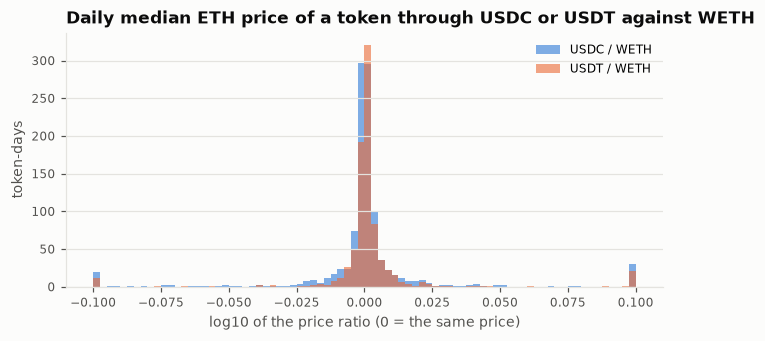

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
for slot, (name, r) in enumerate(ratios.items()):
    ax.hist(r.clip(-0.1, 0.1), bins=80, alpha=0.6, color=plots.SERIES[slot], label=name)
ax.set_xlabel("log10 of the price ratio (0 = the same price)")
ax.set_ylabel("token-days")
ax.set_title("Daily median ETH price of a token through USDC or USDT against WETH")
ax.legend()
plt.show()

## 3. The ETH price

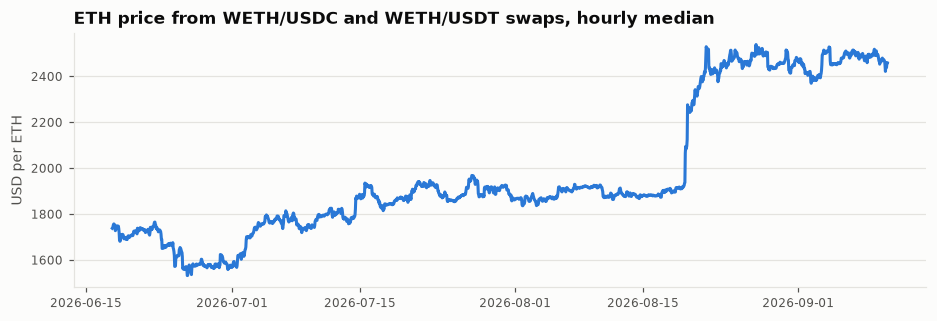

from 1,738 to 2,459 USD; lowest 1,532, highest 2,538


In [5]:
eth = prices.groupby(prices["timestamp"].dt.floor("h"), observed=True)["eth_usd"].median()
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(eth.index, eth.to_numpy(), color=plots.SERIES[0])
ax.set_ylabel("USD per ETH")
ax.set_title("ETH price from WETH/USDC and WETH/USDT swaps, hourly median")
plt.show()
print(f"from {eth.iloc[0]:,.0f} to {eth.iloc[-1]:,.0f} USD; lowest {eth.min():,.0f}, highest {eth.max():,.0f}")

## 4. The price-impact estimate

For a sample of tail-token pools: at a time $s$, the estimate for a trade of a given size from the 7 days before
$s$, against the same estimate made from the 7 days after $s$. Both columns come from the same formula, so this is
a **stability check**, not a test of whether the estimate predicts the move that actually follows a trade. What it
does show: an estimate from last week is rarely far below the one a week later, so the backtest would not trade
much too cheaply because the estimate went stale.

The estimate is capped at 50%. A pool at the cap cannot take a trade of that size at any sensible cost, so the
backtest's positions must stay well below the sizes where most pools hit the cap.

In [6]:
rng = np.random.default_rng(0)
by_pool = prices.groupby("pool", observed=True).size()
sample_pools = rng.choice(by_pool[by_pool >= 500].index.astype(str), size=min(200, int((by_pool >= 500).sum())), replace=False)
pool_prices = bt.PoolPrices(prices[prices["pool"].astype(str).isin(set(sample_pools))].assign(pool=lambda d: d["pool"].astype(str)))
rows = []
for pool in sample_pools:
    arrays = pool_prices.pool(pool)
    if arrays is None or len(arrays["time"]) < 200:
        continue
    s = arrays["time"][len(arrays["time"]) // 2]
    for size in (0.1, 0.5, 2.0):
        before = bt.impact_estimate(arrays, s, size)
        after = bt.impact_estimate(arrays, s + np.timedelta64(7, "D"), size)
        rows.append({"pool": pool, "size_eth": size, "estimate_before": before, "seen_after": after})
impact = pd.DataFrame(rows)
impact.to_csv(OUT / "impact_check.csv", index=False)
impact.groupby("size_eth")[["estimate_before", "seen_after"]].median()

,estimate_before,seen_after
size_eth,,
0.1000,0.0295,0.0270
0.5000,0.1604,0.1626
2.0000,0.5000,0.5000


In [7]:
under = (impact["estimate_before"] < impact["seen_after"] / 2).mean()
print(f"The estimate is less than half of the one a week later in {under:.0%} of pool-sizes.")
capped = impact.groupby("size_eth")["estimate_before"].apply(lambda e: (e >= 0.5).mean())
for size, share in capped.items():
    print(f"  {size:g} ETH: {share:.0%} of sampled pools at the 50% cap")

The estimate is less than half of the one a week later in 6% of pool-sizes.
  0.1 ETH: 10% of sampled pools at the 50% cap
  0.5 ETH: 29% of sampled pools at the 50% cap
  2 ETH: 64% of sampled pools at the 50% cap
